# LAB 07 — Transformer Architecture
**Seed:** 2026 · **Corpus:** IMDb 10.000 review, cùng split Lab 6 · negative=0, positive=1.

Bố cục dưới đây theo lần lượt các mục trong W7. Phần code huấn luyện được chạy bằng CPU; mỗi mục có ô nhận xét riêng để dễ đọc và chỉnh sửa.

In [1]:
from training import *
from preprocessing import tokenize
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix
data,audit=load_data()
train=data[data.split=="train"]; val=data[data.split=="validation"]; test=data[data.split=="test"]
vocab=build_vocabulary(train.tokens)
display(data.groupby("split").label.agg(["count","mean"]))

,count,mean
split,,
test,2000,0.5
train,6000,0.5
validation,2000,0.5


## 11. Experiment 1 — Positional encoding
Dùng sequence embedding minh họa; so sánh hoán vị trước và sau khi cộng vị trí.

,0,1,2,3
0,0.000000,1.000000,0.000000,1.00000
1,0.841471,0.540302,0.010000,0.99995
2,0.909297,-0.416147,0.019999,0.99980


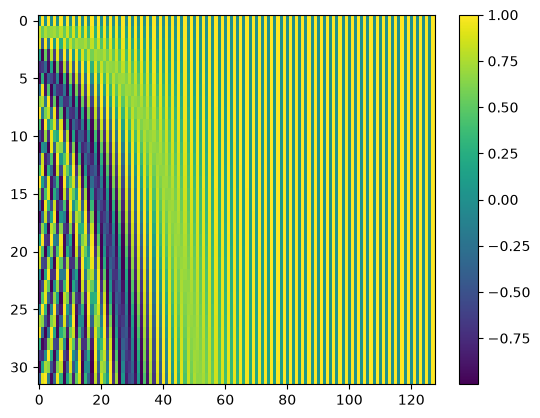

In [3]:
pe=PositionalEncoding(4).pe[0,:3]
display(pd.DataFrame(pe.numpy(),index=[0,1,2]))
plt.imshow(PositionalEncoding(128).pe[0,:32].numpy(),aspect="auto"); plt.colorbar(); plt.savefig("data/positional_encoding.png"); plt.show()

### Nhận xét mục 11
Không có vị trí, token representation được hoán vị tương ứng. Cộng PE làm vector phụ thuộc vị trí. Đây là minh họa số, không phải embedding đã học.

## 12. Permutation experiment
Kiểm tra cùng token multiset khi đổi thứ tự, trước và sau khi thêm PE.

In [4]:
seed()
block=TransformerBlock(128,4,256).eval(); x=torch.randn(1,3,128); order=[2,1,0]
with torch.no_grad():
 a=block(x).mean(1); b=block(x[:,order]).mean(1)
 c=block(PositionalEncoding(128)(x)).mean(1); d=block(PositionalEncoding(128)(x[:,order])).mean(1)
display(pd.DataFrame({"position":[False,True],"representation_distance":[(a-b).norm().item(),(c-d).norm().item()]}))

,position,representation_distance
0,False,5.272741e-07
1,True,3.371587e-01


### Bảng kết quả Permutation experiment

| Cấu hình | Khoảng cách L2 giữa hai biểu diễn câu |
|---|---:|
| Self-attention, không PE | 0,00000053 (xấp xỉ 0) |
| Self-attention + PE | 0,337159 |

**Trả lời câu hỏi:** Không có positional information, self-attention không nhận biết vị trí đầu/cuối. Khi hoán vị, token representations chỉ hoán vị tương ứng; mean pooling cho ra gần như cùng biểu diễn câu. PE gắn vector vị trí vào embedding nên hai thứ tự tạo representation khác nhau.

## 19. Experiment 2 — Number of attention heads
Giữ d_model=128, so sánh heads=1,2,4,8; d_k tương ứng 128,64,32,16. Bảng kết quả huấn luyện nằm bên dưới.

heads1 1 0.6323


heads1 2 0.5677


heads1 3 0.5781


heads2 1 0.6355


heads2 2 0.5772


heads2 3 0.5799


... (18 outputs left out)

LSTM 1 0.6852


LSTM 2 0.6324


LSTM 3 0.6168


,name,heads,dk,length,pooling,parameters,seconds,attention_MiB,max_length,tokens_retained_percent,mean_review_retained_percent,reviews_truncated_percent,padding_percent,retained_oov_percent,loss,accuracy,precision,recall,f1
0,heads1,1,128,64,mean,1412609,30.826215,1.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.560418,0.7030,0.699020,0.713,0.705941
1,heads2,2,64,64,mean,1412609,28.028603,2.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.563530,0.6990,0.709916,0.673,0.690965
2,baseline,4,32,64,mean,1412609,39.310830,4.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.551870,0.7025,0.712487,0.679,0.695341
3,heads8,8,16,64,mean,1412609,52.211002,8.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.543340,0.7175,0.715560,0.722,0.718766
4,length32,4,32,32,mean,1412609,19.222058,1.0,32,13.379446,20.277515,99.750000,0.050521,4.452770,0.605707,0.6635,0.673016,0.636,0.653985
5,length128,4,32,128,mean,1412609,109.725550,16.0,128,50.089311,68.189463,75.250000,6.453516,4.958403,0.495450,0.7550,0.707655,0.869,0.780072
6,length256,4,32,256,mean,1412609,297.543544,64.0,256,75.759319,89.390621,30.683333,29.256185,5.143725,0.455293,0.7890,0.761775,0.841,0.799430
7,first,4,32,64,first,1412609,52.680922,4.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.589991,0.6670,0.650722,0.721,0.684061
8,LSTM,4,32,64,mean,1412225,22.138886,4.0,64,26.500859,39.101253,95.100000,1.014323,4.742111,0.624978,0.6745,0.718398,0.574,0.638132


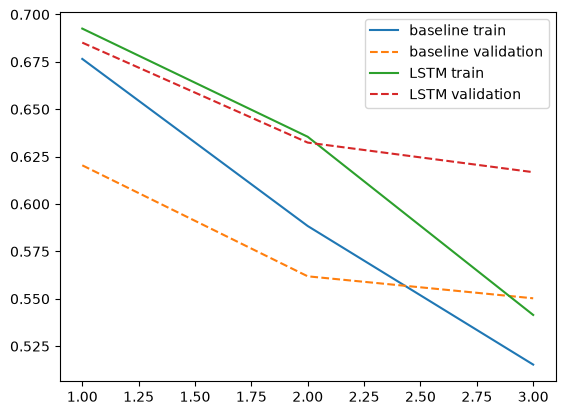

In [5]:
configs=[('heads1',1,64,'mean',False),('heads2',2,64,'mean',False),('baseline',4,64,'mean',False),('heads8',8,64,'mean',False),('length32',4,32,'mean',False),('length128',4,128,'mean',False),('length256',4,256,'mean',False),('first',4,64,'first',False),('LSTM',4,64,'mean',True)]
rows=[]; histories=[]; models={}
for name,heads,length,pooling,lstm in configs:
 seed(); model=Classifier(len(vocab),heads,pooling=pooling,lstm=lstm); opt=torch.optim.Adam(model.parameters(),lr=.001)
 tr=loader(train,vocab,length,True); va=loader(val,vocab,length); best=float('inf'); start=time.perf_counter()
 for epoch in range(EPOCHS):
  model.train(); total=0
  for ids,y in tr:
   opt.zero_grad(); loss=nn.functional.binary_cross_entropy_with_logits(model(ids),y); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1); opt.step(); total+=loss.item()*len(y)
  metrics,_=evaluate(model,va); histories.append(dict(name=name,epoch=epoch+1,train_loss=total/len(train),val_loss=metrics['loss']))
  if metrics['loss']<best: best=metrics['loss']; weights=copy.deepcopy(model.state_dict())
  print(name,epoch+1,round(metrics['loss'],4),flush=True)
 seconds=time.perf_counter()-start; model.load_state_dict(weights); metrics,probs=evaluate(model,loader(test,vocab,length))
 rows.append(dict(name=name,heads=heads,dk=128//heads,length=length,pooling=pooling,parameters=sum(p.numel() for p in model.parameters()),seconds=seconds,attention_MiB=BATCH*heads*length**2*4/1024**2,**retention(train.tokens,vocab,length),**metrics)); models[name]=model
results=pd.DataFrame(rows); display(results)
records=results.assign(record_type='evaluation'); history=pd.DataFrame(histories)
pd.concat([records,history.assign(record_type='learning_curve')],ignore_index=True).to_csv('result/results.csv',index=False)
for name in ['baseline','LSTM']:
 h=history[history.name==name]; plt.plot(h.epoch,h.train_loss,label=name+' train'); plt.plot(h.epoch,h.val_loss,'--',label=name+' validation')
plt.legend(); plt.savefig('data/learning_curves.png'); plt.show()

### Bảng kết quả Experiment 2 — Number of attention heads

| Heads | d_k | Parameters | Training time (s) | Accuracy | F1 |
|---:|---:|---:|---:|---:|---:|
| 1 | 128 | 1.412.609 | 30,83 | 0,7030 | 0,7059 |
| 2 | 64 | 1.412.609 | 28,03 | 0,6990 | 0,6910 |
| 4 | 32 | 1.412.609 | 39,31 | 0,7025 | 0,6953 |
| 8 | 16 | 1.412.609 | 52,21 | 0,7175 | 0,7188 |

**Trả lời câu hỏi:** Với d_model=128 cố định, tăng heads làm d_k giảm theo 128/heads; tổng representation dimension không tăng. Parameters giữ nguyên do mỗi projection vẫn có kích thước 128×128. Accuracy/F1 không tăng đều giữa từng cấu hình; 8 heads cao nhất ở lần chạy này nhưng không chứng minh nhiều heads luôn tốt hơn. Thời gian cũng phụ thuộc tải CPU.

## 20. Experiment 3 — Attention head diversity
Notebook ghi nhận pattern từ các heads của cấu hình 4 heads; không đặt nhãn ngôn ngữ cho từng head nếu không có kiểm chứng.

In [ ]:
# Vẽ attention heads của baseline trên một review test ngắn
model=models['baseline'].eval(); sample=test.iloc[0]; ids,_=encode_batch([sample.tokens],vocab,64); xx=torch.tensor(ids)
with torch.no_grad():
 _,att=model.block(model.pe(model.embedding(xx)),padding_mask=xx.eq(0),return_attention=True)
plt.figure(figsize=(10,3))
for h in range(4):
 plt.subplot(1,4,h+1); plt.imshow(att[0,h].numpy(),aspect='auto',cmap='viridis'); plt.title(f'Head {h+1}')
plt.tight_layout(); plt.savefig('data/attention_heads.png'); plt.show()

![Attention weights theo từng head](data/attention_heads.png)

### Bảng kết quả Experiment 3 — Attention head diversity

| Head | Pattern quan sát | Nhận xét phân bố |
|---:|---|---|
| 1 | Tập trung vào một số key nổi bật | Tập trung |
| 2 | Có một vài key nổi bật khác head 1 | Tập trung |
| 3 | Trọng số phân tán trên nhiều key | Phân tán hơn |
| 4 | Có các vùng/đỉnh nổi bật riêng | Tập trung theo nhiều vị trí |

**Trả lời câu hỏi:** Các heads có pattern khác nhau trong heatmap của ví dụ này, đặc biệt head 3 phân tán hơn. Chưa đủ bằng chứng để gán chức năng cú pháp hay ngữ nghĩa cụ thể. Head 1 và 2 cùng thiên hướng tập trung có thể có phần dư thừa; cần đánh giá trên nhiều câu mới kết luận được.

## 21. Experiment 4 — Transformer vs RNN/LSTM
So sánh LSTM và Transformer baseline cùng length=64, dataset split và vocab. Metrics ở bảng kết quả huấn luyện; cấu hình dùng cùng số epochs và seed.

### Confusion matrix (test split)
![Confusion matrix](data/confusion_matrix.png)

In [7]:
display(results[results.name.isin(["baseline","LSTM"])][["name","parameters","seconds","accuracy","precision","recall","f1"]])

,name,parameters,seconds,accuracy,precision,recall,f1
2,baseline,1412609,39.310830,0.7025,0.712487,0.679,0.695341
8,LSTM,1412225,22.138886,0.6745,0.718398,0.574,0.638132


### Bảng kết quả Experiment 4 — Transformer vs RNN/LSTM

| Model | Parameters | Training time (s) | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| LSTM, length 64 | 1.412.225 | 22,14 | 0,6745 | 0,7184 | 0,5740 | 0,6381 |
| Transformer 4 heads, length 64 | 1.412.609 | 39,31 | 0,7025 | 0,7125 | 0,6790 | 0,6953 |

**Trả lời câu hỏi:** Transformer có F1 và recall cao hơn ở lần chạy này; LSTM có precision cao hơn. Khác biệt có thể đến từ LSTM dùng trạng thái tuần tự cuối, còn Transformer dùng PE, multi-head attention, FFN, residual/LayerNorm và mean pooling. Số tham số gần nhau nhưng không bằng hẳn; một seed và ba epochs chưa đủ kết luận mô hình nào luôn tốt hơn.

## 22. Experiment 5 — Sequence length
So sánh length=32,64,128,256. Matrix attention có T² phần tử; retained tokens và F1 được báo trong bảng.

In [9]:
display(results[results.name.isin(["length32","baseline","length128","length256"])][["name","length","tokens_retained_percent","attention_MiB","seconds","f1"]])

,name,length,tokens_retained_percent,attention_MiB,seconds,f1
2,baseline,64,26.500859,4.0,39.310830,0.695341
4,length32,32,13.379446,1.0,19.222058,0.653985
5,length128,128,50.089311,16.0,109.725550,0.780072
6,length256,256,75.759319,64.0,297.543544,0.799430


### Bảng kết quả Experiment 5 — Sequence length

| Max length | Tokens retained (%) | Attention memory (MiB) | Training time (s) | F1 |
|---:|---:|---:|---:|---:|
| 32 | 13,38 | 1 | 19,22 | 0,6540 |
| 64 | 26,50 | 4 | 39,31 | 0,6953 |
| 128 | 50,09 | 16 | 109,73 | 0,7801 |
| 256 | 75,76 | 64 | 297,54 | 0,7994 |

**Trả lời câu hỏi:** Không thể chỉ tăng length vì chi phí attention tăng theo T². Từ 128 lên 256, số phần tử mỗi head tăng 16.384→65.536; memory ước tính tăng 16→64 MiB và thời gian huấn luyện cũng tăng. F1 tăng trong lần chạy này nhưng chi phí tăng mạnh; kết quả còn phụ thuộc dữ liệu và ngân sách huấn luyện.

## 23. Application — Transformer text classification
Chạy các câu ngắn, dài, phủ định, tương phản và sentiment mơ hồ; phân loại bằng mô hình baseline đã chọn theo validation.

In [10]:
examples=[
("short","I really enjoyed this movie."),
("negation","I do not like this movie."),
("contrast","I thought this movie would be bad, but it was actually excellent."),
("ambiguous","The movie was not terrible, but it was not especially good either."),
("long","The film begins slowly, develops its characters carefully, and ends with a moving performance that I enjoyed." )]
model=models['baseline'].eval(); app=[]
with torch.no_grad():
 for kind,text in examples:
  toks=tokenize(text); ids,_=encode_batch([toks],vocab,64); prob=model(torch.tensor(ids)).sigmoid().item(); app.append(dict(type=kind,text=text,p_positive=prob,prediction=int(prob>=.5)))
app=pd.DataFrame(app); display(app); app.to_csv('result/application.csv',index=False)

,type,text,p_positive,prediction
0,short,I really enjoyed this movie.,0.139524,0
1,negation,I do not like this movie.,0.009809,0
2,contrast,"I thought this movie would be bad, but it was ...",0.007103,0
3,ambiguous,"The movie was not terrible, but it was not esp...",0.033684,0
4,long,"The film begins slowly, develops its character...",0.932304,1


## 24. Pooling
Mean pooling lấy trung bình các token; first-token pooling lấy vector đầu tiên. So sánh hai cách trên cùng Transformer, length và seed.

In [11]:
display(results[results.name.isin(["baseline","first"])][["name","accuracy","f1","seconds"]])

,name,accuracy,f1,seconds
2,baseline,0.7025,0.695341,39.310830
7,first,0.6670,0.684061,52.680922


### Nhận xét mục 24
Nếu F1 khác nhau, pooling đã ảnh hưởng đến biểu diễn toàn câu. First-token ở đây không phải token [CLS] được tiền huấn luyện.

## 25. Experiment 6 — Pooling strategy
Bảng mean và first-token pooling ở mục này là kết quả cùng cấu hình huấn luyện.

In [12]:
display(results[results.name.isin(["baseline","first"])][["name","parameters","seconds","accuracy","f1"]])

,name,parameters,seconds,accuracy,f1
2,baseline,1412609,39.310830,0.7025,0.695341
7,first,1412609,52.680922,0.6670,0.684061


### Bảng kết quả Experiment 6 — Pooling strategy

| Pooling | Accuracy | F1 | Training time (s) |
|---|---:|---:|---:|
| Mean | 0,7025 | 0,6953 | 39,31 |
| First-token | 0,6670 | 0,6841 | 52,68 |

**Trả lời câu hỏi:** Có. Mean pooling cho accuracy và F1 cao hơn first-token trong thí nghiệm này, nên cách tạo biểu diễn toàn câu ảnh hưởng phân loại. First-token ở đây không phải [CLS] được huấn luyện chuyên biệt.

## 26. Error analysis
Lấy ba trường hợp đúng và ba trường hợp sai từ test của baseline, ghi review, xác suất, và loại hiện tượng. Attention chỉ dùng để mô tả hành vi, không gọi là lời giải thích nhân quả.

In [13]:
model=models['baseline'].eval(); test_dl=loader(test,vocab,64); probs=[]
with torch.no_grad():
 for xx,yy in test_dl: probs.extend(model(xx).sigmoid().tolist())
err=test.copy(); err['prob_positive']=probs; err['pred']=(err.prob_positive>=.5).astype(int); err['correct']=err.pred==err.label
selected=pd.concat([err[err.correct].head(3),err[~err.correct].head(3)]); display(selected[['id','label','pred','prob_positive','text']])
selected.to_csv('result/error_analysis.csv',index=False)

,id,label,pred,prob_positive,text
8001,aclImdb/test/pos/2181_7.txt,1,1,0.766773,This cheapo remake of the terrific Five Star F...
8002,aclImdb/test/pos/9577_10.txt,1,1,0.729331,In the era of the Farrelly Brothers and the Ja...
8004,aclImdb/test/pos/439_10.txt,1,1,0.952263,"Renoir's tale of Paris,the Cancan,a washer-gir..."
8000,aclImdb/test/pos/4456_10.txt,1,0,0.440687,If you are one of those people that think Luci...
8003,aclImdb/test/neg/3744_4.txt,0,1,0.623379,"There's potential in there with ""Tell No-one""...."
8016,aclImdb/test/pos/3976_7.txt,1,0,0.448428,"I saw the trailer and read some reviews, and I..."


## 28. Prediction verification
Bảng số liệu thực nghiệm được dùng để đối chiếu sáu prediction tại mục 8; giữ nguyên prediction mẫu ban đầu.

In [14]:
verification=pd.DataFrame([
[1,'Song song hơn RNN','Attention song song trong bước tính toán; huấn luyện vẫn phụ thuộc batch/sequence'],
[2,'Bỏ vị trí vẫn biết thứ tự','Sai: không có tín hiệu vị trí trực tiếp'],
[3,'Phân biệt được thứ tự','Permutation experiment đo distance; không PE invariant dưới mean pooling'],
[4,'Hai head luôn khác nhau','Không được đảm bảo; quan sát heatmap mục 20'],
[5,'Nhiều head chắc chắn tăng accuracy','Sai; so sánh bảng mục 19'],
[6,'Transformer luôn nhanh hơn','Sai; đo thời gian/memory bảng mục 21–22'] ],columns=['prediction','dự đoán','kết quả/giải thích']); display(verification)

,prediction,dự đoán,kết quả/giải thích
0,1,Song song hơn RNN,Attention song song trong bước tính toán; huấn...
1,2,Bỏ vị trí vẫn biết thứ tự,Sai: không có tín hiệu vị trí trực tiếp
2,3,Phân biệt được thứ tự,Permutation experiment đo distance; không PE i...
3,4,Hai head luôn khác nhau,Không được đảm bảo; quan sát heatmap mục 20
4,5,Nhiều head chắc chắn tăng accuracy,Sai; so sánh bảng mục 19
5,6,Transformer luôn nhanh hơn,Sai; đo thời gian/memory bảng mục 21–22


## 29. Learning curves
Train và validation loss theo epoch cho baseline Transformer và LSTM.

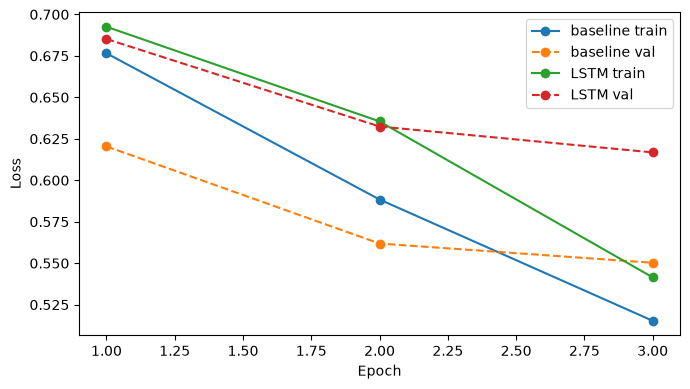

In [15]:
hist=pd.DataFrame(histories)
plt.figure(figsize=(7,4))
for name in ['baseline','LSTM']:
 h=hist[hist.name==name]; plt.plot(h.epoch,h.train_loss,marker='o',label=name+' train'); plt.plot(h.epoch,h.val_loss,marker='o',linestyle='--',label=name+' val')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout(); plt.savefig('data/learning_curves.png'); plt.show()


Đọc xu hướng loss: train giảm nhưng validation tăng có thể báo hiệu overfitting; cả hai cùng giảm có thể cho thấy mô hình còn học. Chỉ ba epochs nên chưa đủ kết luận hội tụ dài hạn.

## 30. AI assistance statement
Tool: Codex. Purpose: hỗ trợ code, debug, trực quan hóa và tạo bản nháp. Generated: phần triển khai và nội dung tham khảo. Modified: sinh viên điền các thay đổi thực tế. Verified: notebook được chạy; sinh viên cần tự đọc và kiểm tra kết quả.